In [1]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/data_exploration/../../../models/hgm.py'>

In [3]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


gcamp = True
# read_ids_gcamp = list(range(0, 33+1))
read_ids_gcamp = [0,   # minrevs
				  1,   # minswitch
				  7,   # maxswitch
				  11,  # median
				  12,  # maxrevs
				  17,  # mean
				  19,  # paper
				  21]  # clean
# read_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	# read_ids_gfp = list(range(0, 7+1))
	read_ids_gfp = [2, 4, 6]
	# read_ids_gfp = [2]
	plot_id_gfp = 2


artificial = True
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path_gfp, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# remove unused discrete state labels
	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])


# generate
if artificial:
	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_gcamp[i],
														 discrete_states_gcamp[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gcamp[i])

		discrete_states_art.append(discrete_states_gcamp[i].copy())
		eigenworms_art.append(eigenworms_gcamp[i].copy())

In [5]:
selection_n_gcamp = [label for label in selection_n if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]
if gfp:
	selection_n_gfp = [label for label in selection_n if label in traces_gfp[file_ids_gfp.index(plot_id_gfp)].columns]

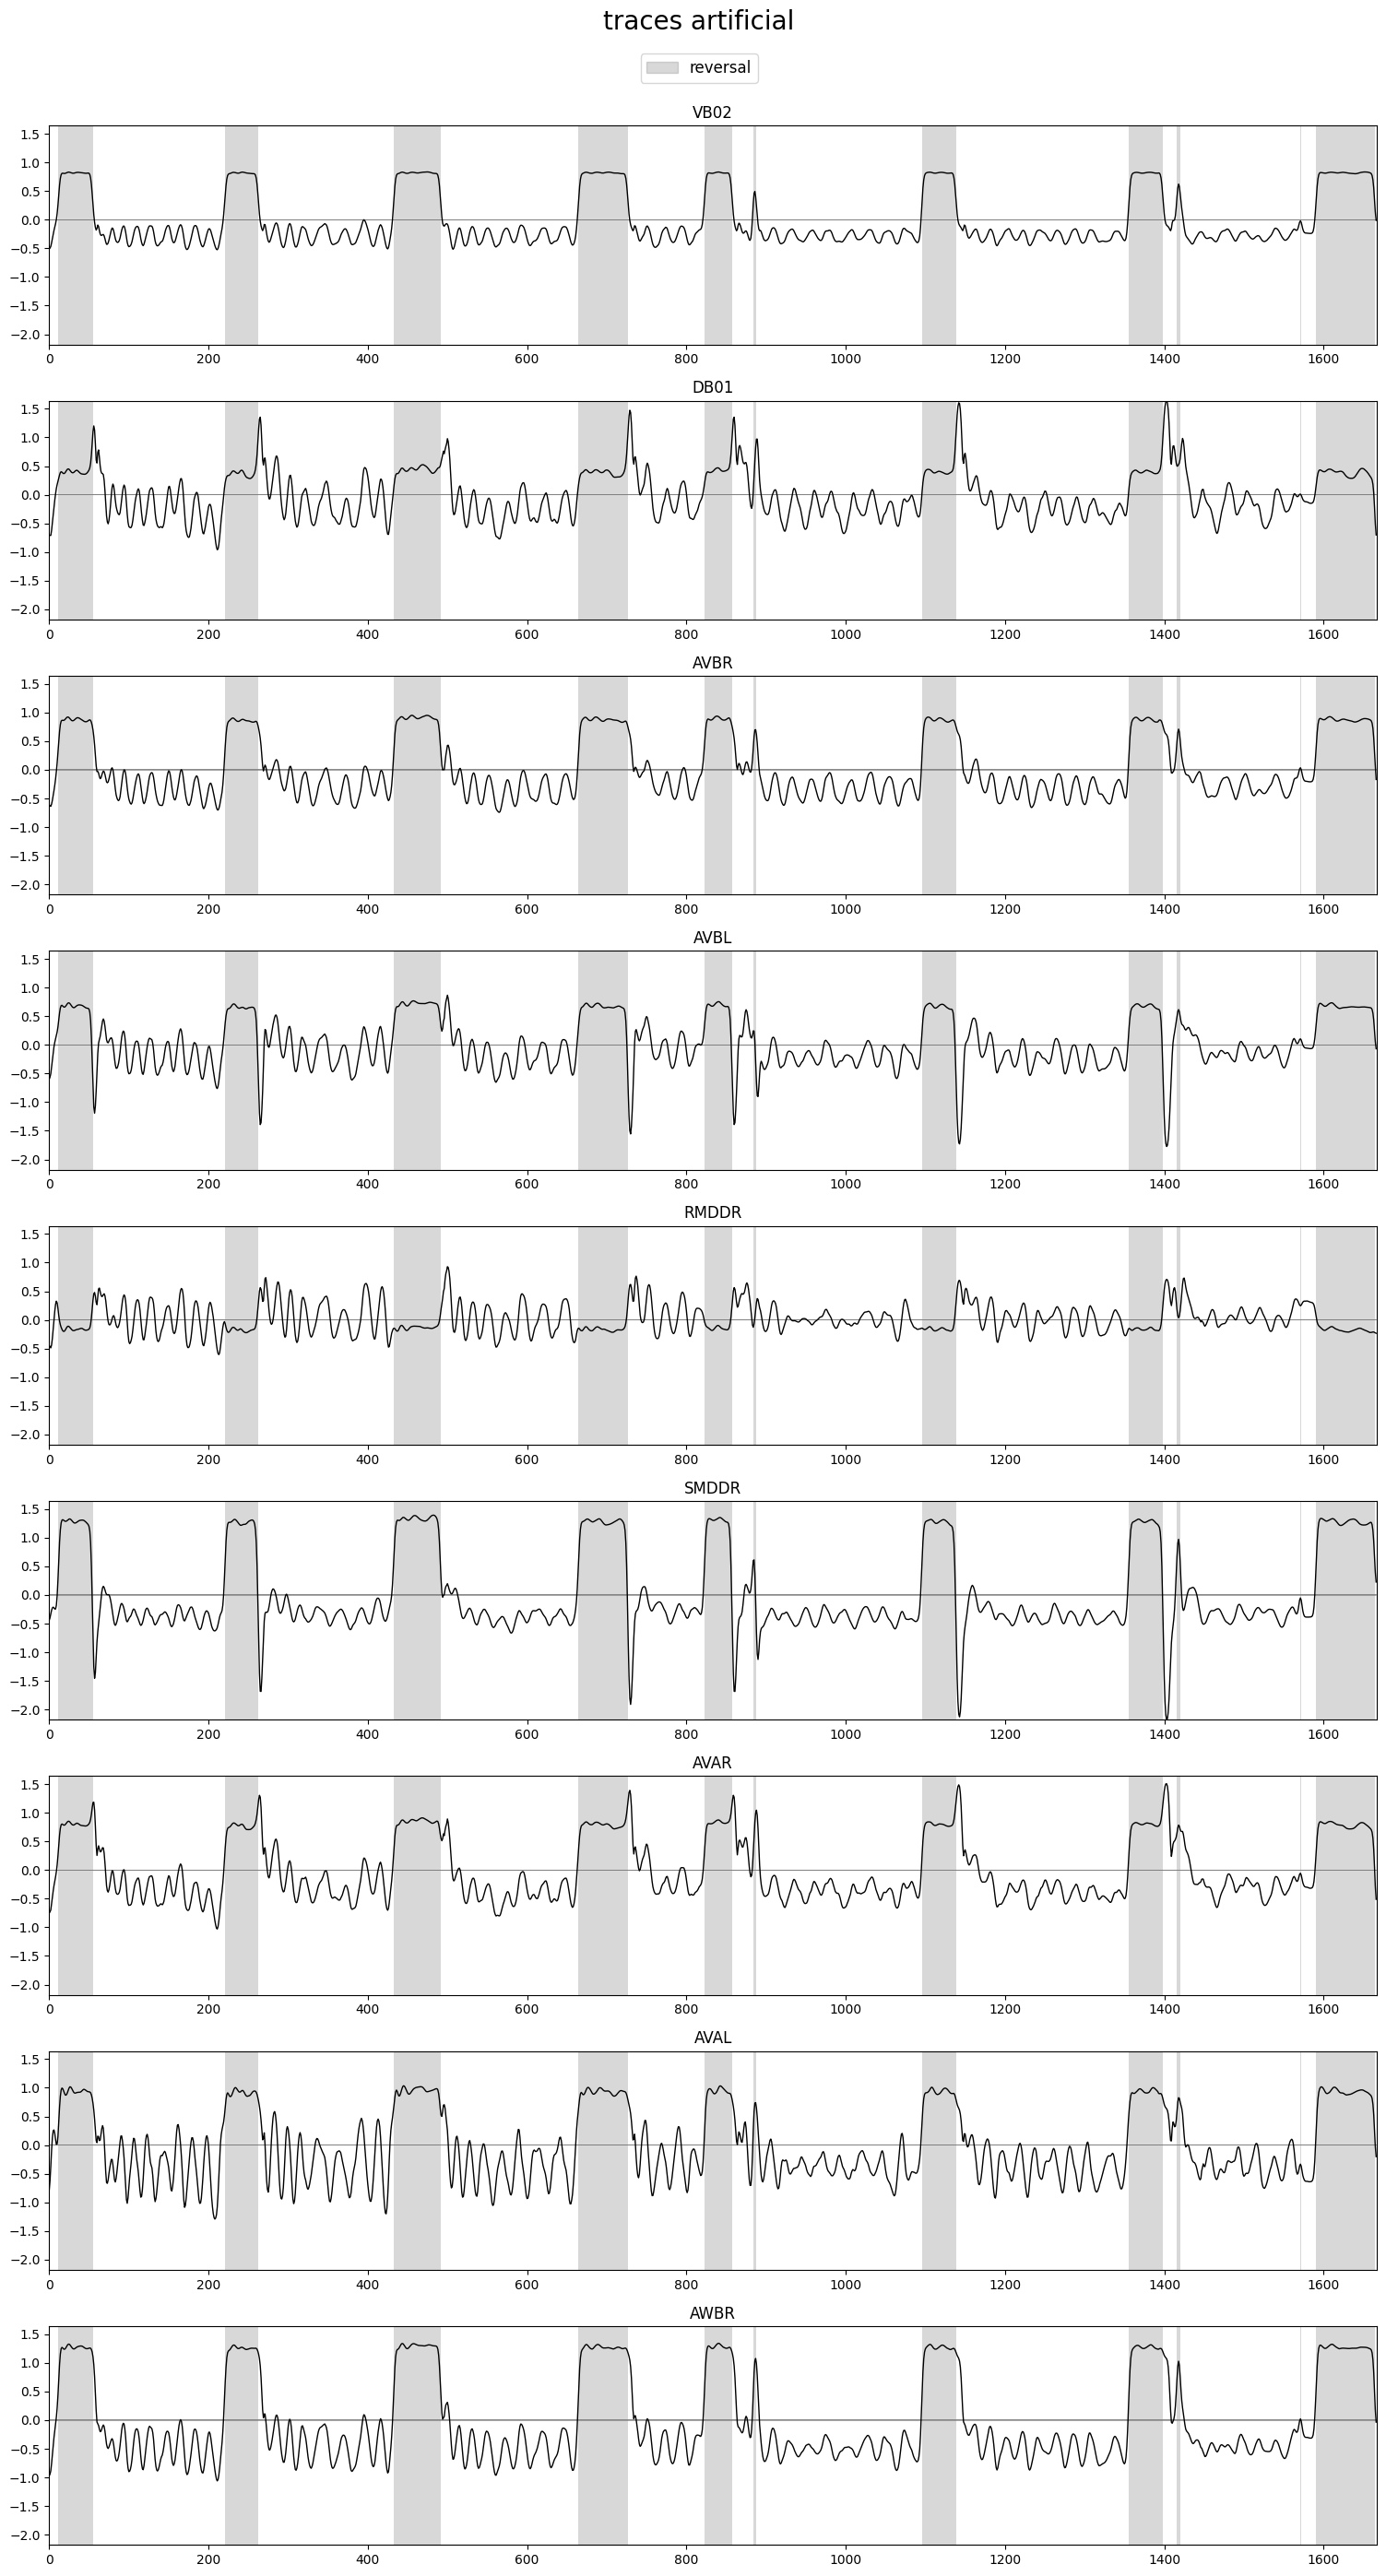

In [6]:
if artificial:
	plot_utils.plot_traces('traces artificial',
						   discrete_states_art[file_ids_art.index(plot_id_gcamp)][['REV']],
						   traces_art[file_ids_art.index(plot_id_gcamp)][selection_n_gcamp],
						   n_plots=None, plots_per_row=1, ylimits=None)

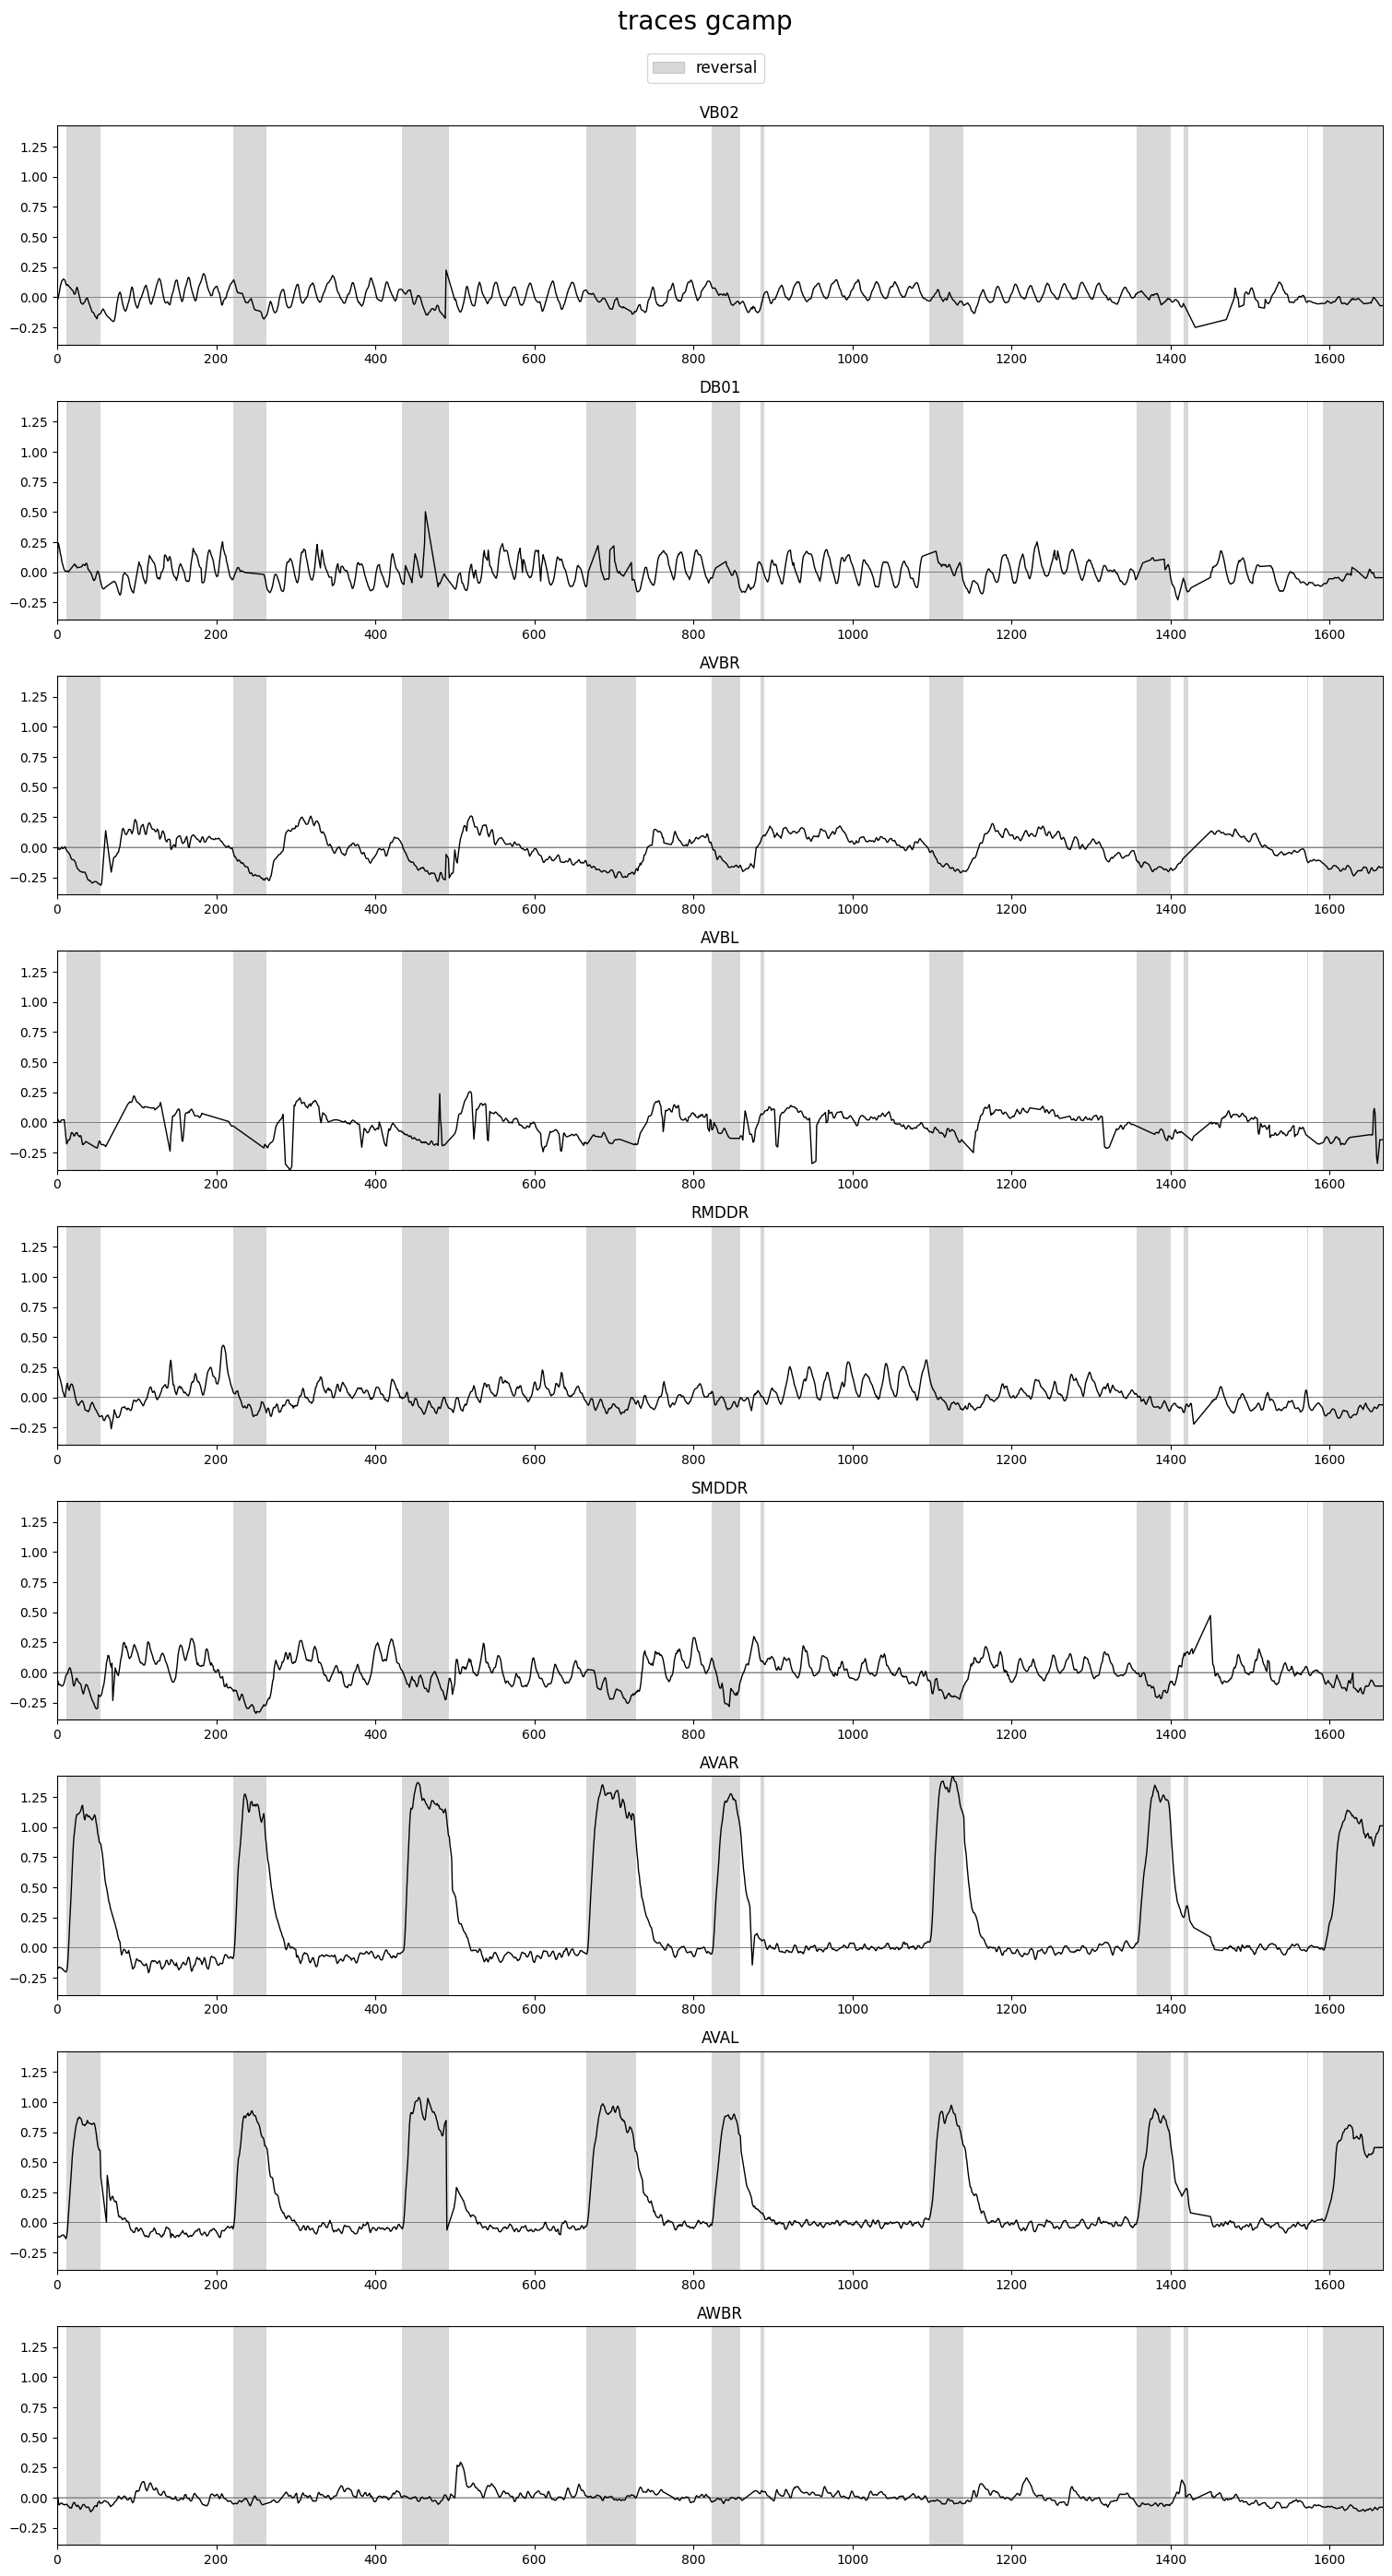

In [7]:
plot_utils.plot_traces('traces gcamp',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
					   traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_gcamp],
					   n_plots=None, plots_per_row=1, ylimits=None)

In [10]:
for i, trace in enumerate(traces_gcamp):
	print(np.median(trace.values, axis=0))

[-9.93001236e-05  1.37144281e-03  6.16987639e-04  2.84591875e-04
 -2.82137729e-05  1.15324792e-04 -7.67018059e-04  3.16782168e-03
 -6.23423891e-03 -1.97607395e-04 -4.61922136e-03  3.30558141e-03
 -2.64552472e-03  1.56066890e-03  4.00693765e-03  2.05160353e-03
 -2.57016282e-03 -3.64624795e-04 -2.68760051e-03 -1.23673354e-04
 -9.71407248e-04  1.56166474e-03  2.03743575e-04  2.21443823e-04
  1.48898495e-03  1.48333348e-03  2.28321711e-03  1.42775070e-03
  3.62593974e-03  5.55885054e-03  2.32837028e-03  2.50543982e-04
  2.17631151e-03  7.12012264e-04  3.62043777e-03  5.73826145e-04
  1.38146298e-03 -1.12645182e-04  4.88055128e-04 -4.09061139e-04
 -4.79493768e-04  1.98368455e-03 -2.29908386e-03  9.74187956e-04
  4.06073571e-04  8.39021696e-03  3.51037252e-03  3.97408191e-04
 -1.48835341e-03  1.14081323e-03 -2.79823364e-03 -4.16881087e-04
 -5.07663670e-03  6.22895531e-04  9.15146641e-04 -2.08905668e-03
  6.28178997e-04 -1.96338259e-03 -1.84443473e-03  1.10030536e-03
 -1.77706327e-03  1.26727

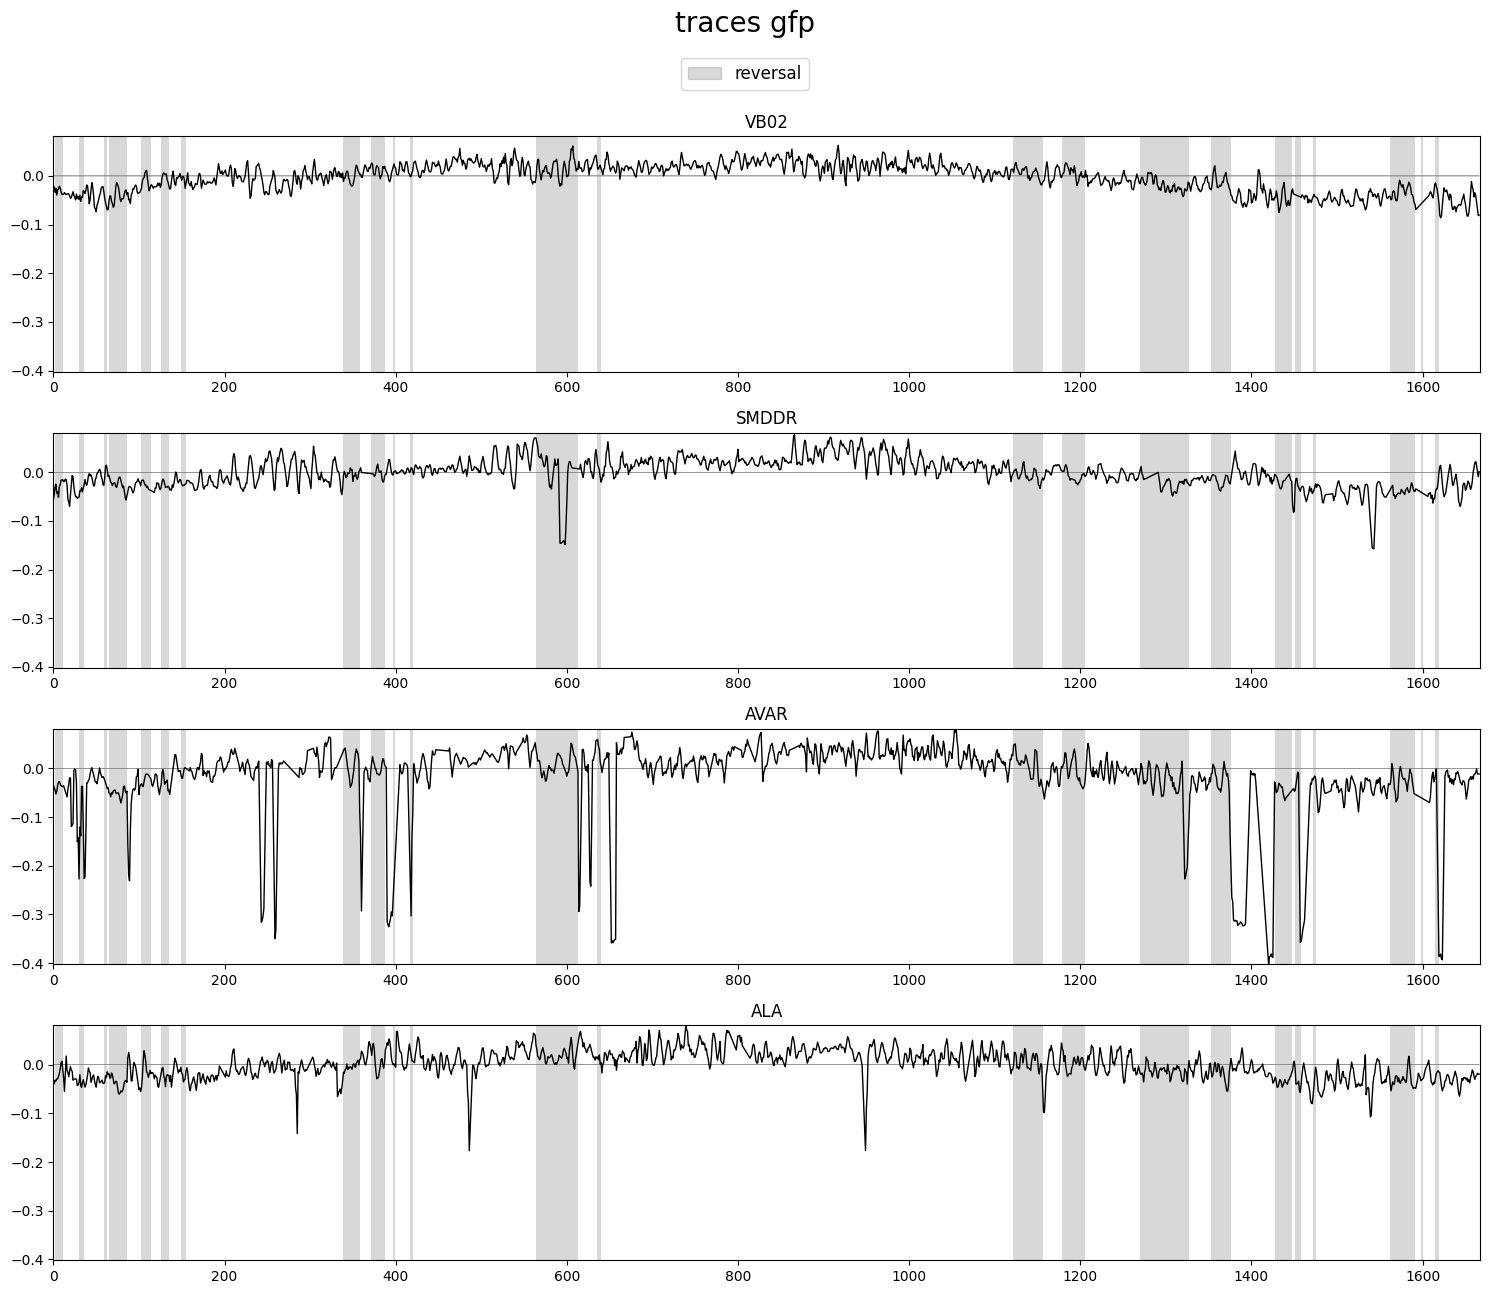

In [8]:
if gfp:
	plot_utils.plot_traces('traces gfp',
						   discrete_states_gfp[file_ids_gfp.index(plot_id_gfp)][['REV']],
						   traces_gfp[file_ids_gfp.index(plot_id_gfp)][selection_n_gfp],
						   n_plots=None, plots_per_row=1, ylimits=None)